# Los seis choques de Basilea paso a paso: el escalar 0,417, el empinamiento de +25,4 pb y el aplanamiento de -1,6 pb

**Pregunta:** el estándar convierte tres tamaños por moneda en seis formas de choque de tasa; ¿cómo mueve cada forma las 19 bandas de una curva cero en dólares, cuánto movió la recalibración de 2024 a las rotaciones, y en qué bandas un piso en cero detiene a los choques a la baja?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (las 19 bandas, la brecha y el EVE)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- construir cada una de las seis formas de choque estándar (paralelo al alza y a la baja, corto al alza y a la baja, empinamiento, aplanamiento) desde sus dos escalares y sus tamaños, y leer cada intermedio;
- reproducir con el motor el ejemplo resuelto del estándar (0,417, +41,7 pb, +25,4 pb y -1,6 pb a 3,5 años) y leer la prueba de valores de referencia que lo guarda;
- decir de dónde vienen los tamaños (las tablas de 2016 y de 2024, y la tabla del regulador chileno) y qué hace el motor cuando una moneda no tiene tamaño;
- aplicar un piso posterior al choque y decir en qué bandas actúa, con el piso en cero y con el piso dependiente del plazo de la Unión Europea.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Tres documentos versionados alimentan el notebook:

- `data/derived/C14/vd-2022-q2.json` (caso C14, el banco que quebró en 2023, al 2022-06-30): los cuatro bloques de escenarios con las seis formas de choque en puntos base en los 19 puntos medios, los pisos, la curva cero y las filas de pruebas versionadas. Fuentes: reportes de condición de la FDIC y curva a la par del Tesoro de EE. UU., ambas `mirror-allowed`; real en agregado, sintético en comportamiento.
- `data/derived/C14/models-svb-2021-2022.json`: las tablas de choques como fixtures (la calibración de 2016 de BCBS d368 y la de 2024 vigente desde 2026-01-01) y las constantes de las formas.
- `data/derived/C15/short-uf.json` (caso C15, el Banco Andino sintético sobre un balance en pesos y UF): los tamaños de choque del regulador chileno para el peso y la UF. Fuentes: la CMF (RAN 21-13 Anexo 1) y las curvas del Banco Central de Chile, `mirror-allowed`; el banco es sintético.

Los tamaños de choque están en puntos base. La celda siguiente carga los tres documentos.

In [2]:
# Cargar los tres documentos (el notebook está tres carpetas bajo la raíz del repositorio) y los 19 puntos medios
ROOT = Path("../../..").resolve()
c14 = json.loads((ROOT / "data" / "derived" / "C14" / "vd-2022-q2.json").read_text(encoding="utf-8"))
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
out14, out15 = c14["outputs"], c15["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
NAME = {"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento"}
NAME.update({"flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja"})
print("fecha de valoración de C14:", out14["valuation_date"], "| C15:", out15["as_of"])
print("orden de los seis choques en el motor:", shocks.SHOCKS)

fecha de valoración de C14: 2022-06-30 | C15: 2026-09-03
orden de los seis choques en el motor: ('parallel-up', 'parallel-down', 'steepener', 'flattener', 'short-up', 'short-down')


## Método

El método tiene seis pasos: (1) los dos escalares, (2) las seis formas, (3) el ejemplo resuelto del estándar y la prueba de valores de referencia del motor, (4) los tamaños por moneda y calibración, (5) las formas en los 19 puntos medios, (6) los pisos posteriores al choque.

### Paso 1: los dos escalares

Toda forma se construye con un escalar decreciente para el extremo corto y su complemento para el extremo largo. Con $t_k$ el punto medio de la banda $k$ en años y $x = 4$ (SRP31.91, nota 8: "$x = 4$ para la mayoría de las monedas salvo que los supervisores nacionales determinen otra cosa"):

$$\alpha_{corto}(t_k) = e^{-t_k / x}, \qquad \alpha_{largo}(t_k) = 1 - e^{-t_k / x}$$

(fuente: BCBS, SRP31.91 y SRP31.92, https://www.bis.org/basel_framework/chapter/SRP/31.htm; dossier 01, H.2). El escalar corto es casi uno en el extremo corto y decae; el escalar largo es su complemento, así que los dos suman siempre uno. La función `shock_scalars` del motor devuelve ambos para cualquier lista de plazos. La celda siguiente los imprime en algunos de los 19 puntos medios.

escalares a 3,5 años (corto, largo): 0.4169 0.5831


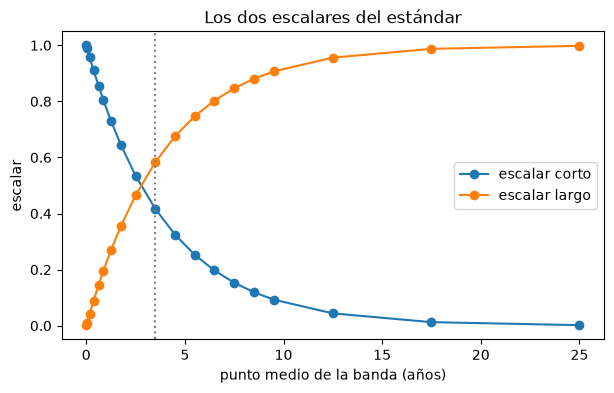

In [3]:
# Los dos escalares en los 19 puntos medios, dibujados, y su valor en los 3,5 años del ejemplo del estándar
alpha_short, alpha_long = shocks.shock_scalars(MID)
at_35 = shocks.shock_scalars(np.array([3.5]))
print("escalares a 3,5 años (corto, largo):", round(float(at_35[0][0]), 4), round(float(at_35[1][0]), 4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(MID, alpha_short, marker="o", label="escalar corto")
ax.plot(MID, alpha_long, marker="o", label="escalar largo")
ax.axvline(3.5, color="grey", linestyle=":")
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("escalar")
ax.set_title("Los dos escalares del estándar")
ax.legend()
plt.show()

El escalar corto parte en casi uno en la banda a la vista y cae a casi cero a los 25 años; el escalar largo es su imagen en espejo, y la línea punteada marca los 3,5 años, donde el escalar corto vale 0,4169 y el largo 0,5831, como dice la impresión de arriba. Como siempre suman uno, una rotación que los pondera distinto puede bajar el extremo corto y subir el largo sin salir de la tabla de tamaños. La imagen muestra solo los escalares; los tamaños que los multiplican llegan en el paso 4, y un escalar de 0,9 en el extremo corto no es un choque de 90 puntos base.

### Paso 2: las seis formas

Con los tres tamaños de una moneda, el paralelo $\bar S_{par}$, el corto $\bar S_{corto}$ y el largo $\bar S_{largo}$ (en puntos base), las seis formas son (BCBS, SRP31.90 a SRP31.92; dossier 01, H.2):

$$\Delta S_{par}(t_k) = \pm \bar S_{par}, \qquad \Delta S_{corto}(t_k) = \pm \bar S_{corto}\, \alpha_{corto}(t_k), \qquad \Delta S_{largo}(t_k) = \pm \bar S_{largo}\, \alpha_{largo}(t_k)$$

$$\Delta S_{emp}(t_k) = -0{,}65\, |\Delta S_{corto}(t_k)| + 0{,}9\, |\Delta S_{largo}(t_k)|$$

$$\Delta S_{apl}(t_k) = +0{,}8\, |\Delta S_{corto}(t_k)| - 0{,}6\, |\Delta S_{largo}(t_k)|$$

El choque largo se usa solo dentro de las dos rotaciones: las seis formas de escenario del motor son paralelo al alza y a la baja, corto al alza y a la baja, empinamiento y aplanamiento. El empinamiento baja el extremo corto y sube el largo, el aplanamiento hace lo contrario. La celda siguiente resuelve a mano el ejemplo del propio estándar en el punto medio de 3,5 años con los tamaños corto y largo en 100 pb, imprimiendo cada intermedio, y luego pide al motor las mismas formas con `shock_curve`. Es una verificación de la definición en un punto, no una segunda implementación de la función; el motor sigue siendo el método.

In [4]:
# El ejemplo resuelto de SRP31.92 a mano a 3,5 años, y la forma del motor para cada uno de los seis choques
t = np.array([3.5])
a_short, a_long = shocks.shock_scalars(t)
size = 100.0
short_abs, long_abs = size * a_short[0], size * a_long[0]
print("escalar corto a 3,5 años:", round(float(a_short[0]), 4), "| escalar largo:", round(float(a_long[0]), 4))
print("|choque corto| =", round(float(short_abs), 2), "pb | |choque largo| =", round(float(long_abs), 2), "pb")
steep_hand = -0.65 * short_abs + 0.9 * long_abs
flat_hand = 0.8 * short_abs - 0.6 * long_abs
by_hand = {"short-up": short_abs, "steepener": steep_hand, "flattener": flat_hand}
for shock in shocks.SHOCKS:
    value = float(shocks.shock_curve(shock, size, size, size, t)[0])
    hand = f" | a mano {by_hand[shock]:8.4f}" if shock in by_hand else ""
    print(f"{NAME[shock]:22s} motor {value:9.4f} pb{hand}")

escalar corto a 3,5 años: 0.4169 | escalar largo: 0.5831
|choque corto| = 41.69 pb | |choque largo| = 58.31 pb
paralelo al alza       motor  100.0000 pb
paralelo a la baja     motor -100.0000 pb
empinamiento           motor   25.3864 pb | a mano  25.3864
aplanamiento           motor   -1.6393 pb | a mano  -1.6393
corto al alza          motor   41.6862 pb | a mano  41.6862
corto a la baja        motor  -41.6862 pb


### Paso 3: la prueba de valores de referencia del ejemplo del estándar

El estándar imprime su ejemplo con precisión redondeada: 0,417, +41,7 pb, +25,4 pb y -1,6 pb. El motor guarda esos cuatro valores como una prueba de validación, `irrbb.srp31_92_goldens`, que los recalcula y los compara con los impresos dentro de una tolerancia de 0,0005 para el escalar y 0,05 pb para las formas (un umbral interno de Contraste, no regulatorio). El estadístico es la mayor desviación absoluta. La celda siguiente corre la prueba, imprime cada valor junto a su par impreso y dibuja cada desviación como fracción de su tolerancia.

test_id: irrbb.srp31_92_goldens | n = 4 | mayor desviación: 0.0393
                  motor    impreso   desviación
alpha_short      0.4169     0.4170       0.0001
short-up        41.6862    41.7000       0.0138
steepener       25.3864    25.4000       0.0136
flattener       -1.6393    -1.6000       0.0393
tolerancias: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.05}


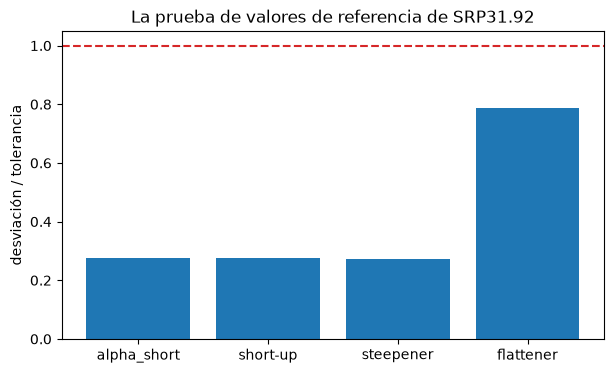

In [5]:
# Correr la prueba de valores de referencia de SRP31.92 y dibujar cada desviación como fracción de su tolerancia
golden = rv_irrbb.srp31_92_goldens()
values, printed = golden.extras["values"], golden.extras["printed"]
dev, tol = golden.extras["deviations"], golden.extras["thresholds"]
print("test_id:", golden.test_id, "| n =", golden.n, "| mayor desviación:", round(golden.statistic, 4))
print(f"{'':12s} {'motor':>10s} {'impreso':>10s} {'desviación':>12s}")
for name in values:
    print(f"{name:12s} {values[name]:10.4f} {printed[name]:10.4f} {dev[name]:12.4f}")
print("tolerancias:", tol)
limit = {n: tol["tolerance_scalar"] if n.startswith("alpha") else tol["tolerance_bp"] for n in values}
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(values), [dev[n] / limit[n] for n in values], color="tab:blue")
ax.axhline(1.0, color="tab:red", linestyle="--")
ax.set_ylabel("desviación / tolerancia")
ax.set_title("La prueba de valores de referencia de SRP31.92")
plt.show()

Todas las barras quedan bien bajo la línea roja en uno, que es la tolerancia de su propio valor: la mayor, el aplanamiento, usa unos cuatro quintos de los 0,05 pb que se le permiten, y el escalar usa un quinto de 0,0005. El estándar imprime un decimal, así que un aplanamiento de -1,6393 frente a un -1,6 impreso es una desviación de 0,0393 que es redondeo y no error. La prueba dice entonces "igual a la precisión impresa", que es lo que una prueba de valores de referencia de una fuente redondeada puede decir; no dice que el motor acierte en otros puntos u otros tamaños, que es lo que muestran los pasos siguientes sobre la moneda del propio banco.

### Paso 4: los tamaños por moneda y calibración

Los tamaños son una tabla, no una fórmula. El Comité de Basilea los calibró sobre cambios históricos de tasas y publicó dos tablas: la de 2016 (BCBS d368, Anexo 2, Tabla 1: datos de 2000 a 2015, percentil 99 de factores globales, redondeada a 50 pb) y la de 2024 que la reemplaza desde 2026-01-01 (SRP31.90, Tabla 2, d578: datos de enero de 2000 a diciembre de 2023, percentil 99,9 de cambios absolutos promedio de seis meses locales, redondeada a 25 pb). El regulador chileno publica su propia tabla en el Anexo 1 de la RAN 21-13, que es la que usa el caso chileno. El motor guarda las tres como datos: `shock_table` devuelve los tamaños de una calibración como `{moneda: (paralelo, corto, largo)}`. La celda siguiente imprime tres monedas en las dos calibraciones de Basilea y las cinco filas de la tabla chilena (un guion en la fuente es un valor faltante).

monedas en las tablas de 2016 y 2024: 21 21
CLP en la tabla de 2024: no
filas de la tabla chilena:
  canasta-1  (200.0, 300.0, 150.0)
  canasta-2  (400.0, 500.0, 300.0)
  CLP        (300.0, 400.0, 200.0)
  UR-nii     (300.0, None, None)
  UR-eve     (200.0, 250.0, 150.0)


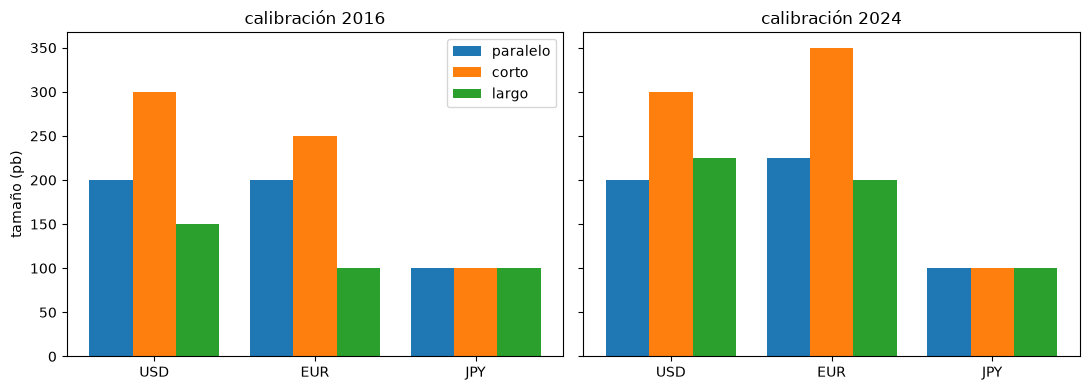

In [6]:
# Tamaños en puntos base de tres monedas bajo las dos calibraciones de Basilea, y las filas de la tabla chilena
t2016, t2024 = shocks.shock_table("2016"), shocks.shock_table("2024")
tcmf = shocks.shock_table("cmf-annex1")
currencies = ("USD", "EUR", "JPY")
has_clp = ("no", "sí")["CLP" in t2024]
print("monedas en las tablas de 2016 y 2024:", len(t2016), len(t2024))
print("CLP en la tabla de 2024:", has_clp)
print("filas de la tabla chilena:")
for row, sizes in tcmf.items():
    print(f"  {row:10s} {sizes}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, table, year in zip(axes, (t2016, t2024), ("2016", "2024")):
    for j, kind in enumerate(("paralelo", "corto", "largo")):
        ax.bar(np.arange(3) + 0.27 * (j - 1), [table[c][j] for c in currencies], 0.27, label=kind)
    ax.set_xticks(np.arange(3), currencies)
    ax.set_title("calibración " + year)
axes[0].set_ylabel("tamaño (pb)")
axes[0].legend()
fig.tight_layout()
plt.show()

Los dos paneles difieren donde corresponde: para el dólar solo crece la barra larga entre 2016 y 2024 (150 a 225 pb), para el euro crecen las tres, y para el yen ninguna se mueve. Ninguna tabla de Basilea trae el peso chileno, lo que la impresión muestra con su cuenta de monedas y con la respuesta a la pregunta por CLP, y la tabla del regulador chileno tiene sus propias filas, entre ellas una fila de canasta 1 con 200, 300 y 150 pb. De ahí se sigue que un tamaño es un número con dueño: de qué tabla viene decide el resultado tanto como la forma, y la figura muestra solo tres de las veintiuna monedas.

Lo que hace el motor con una moneda sin entrada es una decisión de diseño que vale la pena leer. `shock_size` devuelve el tamaño de una moneda con su **origen** (de qué tabla vino). Para una moneda sin entrada **se niega**: un tamaño nunca se inventa. El llamador puede dar una estimación, pero entonces el tamaño lleva el origen `contraste-estimate`, una etiqueta bilingüe y el método, de modo que ninguna estimación pueda pasar por un parámetro regulatorio; y una moneda con tamaño tabulado rechaza una estimación. La celda siguiente muestra los tres casos: el peso en la tabla de Basilea (rechazado), el peso y la UF en la tabla chilena (tabulados; la UF toma la fila `UR-eve`) y una ilustración de la estimación rotulada para el peso, que solo muestra el mecanismo y el producto no usa.

In [7]:
# El tamaño de una moneda con su origen: rechazado sin entrada, tabulado en la tabla chilena y una estimación rotulada
try:
    shocks.shock_size("CLP", "2024")
except ValueError as error:
    print("el motor rechaza un tamaño para CLP en la tabla de 2024:", type(error).__name__)
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency}: paralelo, corto, largo = {z.parallel_bp:.0f}, {z.short_bp:.0f}, {z.long_bp:.0f} pb")
    print(f"  origen = {z.origin}")
label = {"en": "solo ilustración", "es": "solo ilustración"}
estimate = (300.0, 400.0, 200.0, label, "ilustración de la ruta de la estimación rotulada")
z = shocks.shock_size("CLP", "2024", estimate=estimate)
print("estimación rotulada: origen =", z.origin, "|", z.label[LANG])
used = [(u["currency"], u["parallel_bp"], u["short_bp"], u["long_bp"]) for u in out15["eve_shock_sizes"]]
print("tamaños que el caso chileno C15 lee para el EVE:", used)

el motor rechaza un tamaño para CLP en la tabla de 2024: ValueError
CLP: paralelo, corto, largo = 300, 400, 200 pb
  origen = cmf-annex1
CLF: paralelo, corto, largo = 200, 250, 150 pb
  origen = cmf-annex1
estimación rotulada: origen = contraste-estimate | solo ilustración
tamaños que el caso chileno C15 lee para el EVE: [('CLP', 300.0, 400.0, 200.0), ('CLF', 200.0, 250.0, 150.0)]


### Paso 5: las seis formas en los 19 puntos medios

Ahora las seis formas para el USD bajo la calibración 2024 (200, 300 y 225 pb) en los 19 puntos medios con `shock_curve`, dibujadas contra los puntos medios. La misma celda construye el empinamiento de la calibración 2016 (tamaño largo 150 pb en vez de 225), para mostrar cuánto mueve la recalibración a una rotación.

                          banda 1    banda 10    banda 19
paralelo al alza           200.00      200.00      200.00
paralelo a la baja        -200.00     -200.00     -200.00
empinamiento              -194.72       36.80      201.73
aplanamiento               239.74       21.32     -134.28
corto al alza              299.79      125.06        0.58
corto a la baja           -299.79     -125.06       -0.58
empinamiento en la banda 19 con los tamaños de 2016: 134.36 pb
tamaños de 2024: 201.73 pb


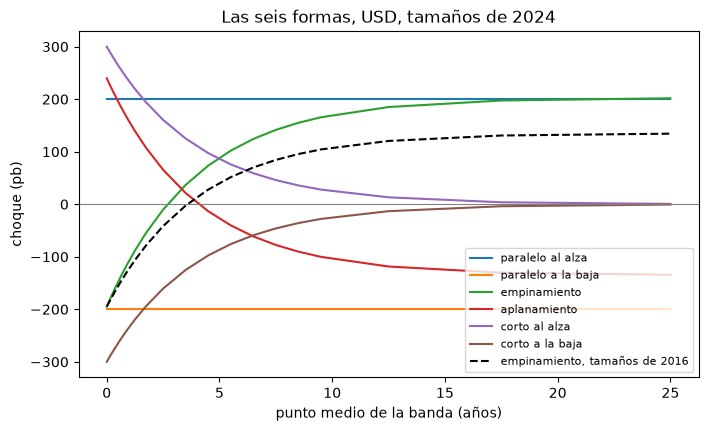

In [8]:
# Las seis formas del USD bajo la calibración 2024 en los 19 puntos medios, y el empinamiento con los tamaños de 2016
size24 = shocks.shock_size("USD", "2024")
size16 = shocks.shock_size("USD", "2016")
sizes24 = (size24.parallel_bp, size24.short_bp, size24.long_bp)
shapes = {s: shocks.shock_curve(s, *sizes24, MID) for s in shocks.SHOCKS}
steep16 = shocks.shock_curve("steepener", size16.parallel_bp, size16.short_bp, size16.long_bp, MID)
print(f"{'':22s} {'banda 1':>10s} {'banda 10':>11s} {'banda 19':>11s}")
for s in shocks.SHOCKS:
    print(f"{NAME[s]:22s} {shapes[s][0]:10.2f} {shapes[s][9]:11.2f} {shapes[s][18]:11.2f}")
steep24 = shapes["steepener"][18]
print("empinamiento en la banda 19 con los tamaños de 2016:", round(float(steep16[18]), 2), "pb")
print("tamaños de 2024:", round(float(steep24), 2), "pb")
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in shocks.SHOCKS:
    ax.plot(MID, shapes[s], label=NAME[s])
ax.plot(MID, steep16, color="black", linestyle="--", label="empinamiento, tamaños de 2016")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("choque (pb)")
ax.set_title("Las seis formas, USD, tamaños de 2024")
ax.legend(fontsize=8)
plt.show()

Los choques cortos se desvanecen con el horizonte, de 300 pb a la vista a casi nada a los 25 años; los choques paralelos quedan planos en 200 pb; y las dos rotaciones cruzan el cero en horizontes distintos. El empinamiento baja el extremo corto casi los 200 pb completos y sube el largo sobre 200, y la línea punteada muestra cuánto de ese extremo largo viene de la recalibración: con el tamaño largo de 150 pb de 2016 llega a 134 pb a los 25 años, con el de 225 pb de 2024 llega a 202. El aplanamiento es el espejo, grande en el extremo corto y negativo en el largo. La imagen muestra una moneda con una calibración y no dice cuál forma es la peor para un balance particular, lo que depende de dónde estén sus brechas.

### Paso 6: los pisos posteriores al choque

Un choque a la baja grande sobre una tasa baja la llevaría muy por debajo de cero. El estándar deja que los supervisores pongan a las tasas posteriores al choque un piso no superior a cero (SRP31.93), y la función `apply_floor` del motor aplica

$$r_{choque} = \max\left(r_0 + \frac{s}{10^4},\ \min(f,\ r_0)\right)$$

donde $s$ es el choque en puntos base, $r_0$ la tasa base y $f$ el piso: un piso nunca eleva una tasa por encima de su propio valor previo al choque, así que una tasa que ya está bajo el piso conserva su valor. El piso puede ser un número o un valor por banda. Además del piso en cero, el motor guarda el piso dependiente del plazo de la Unión Europea, `eu_floor`: $-1{,}5\%$ a plazo inmediato, que sube 0,03 puntos porcentuales por año hasta cero a los 50 años (Reglamento Delegado (UE) 2024/856 de la Comisión, artículo 3(7), según lo cita el motor; dossier 01, H.5). La celda siguiente aplica el piso en cero a la curva cero del USD al 2022-06-30 bajo el choque paralelo a la baja de 200 pb, y luego lista las bandas donde el piso actúa bajo cada uno de los seis choques.

 banda    tasa base con choque, sin piso   con choque, piso 0
     1      0.01279             -0.00721              0.00000
     2      0.01279             -0.00721              0.00000
     3      0.01678             -0.00322              0.00000
     4      0.02105              0.00105              0.00105
     5      0.02566              0.00566              0.00566
paralelo al alza       bandas donde el piso en cero actúa: []
paralelo a la baja     bandas donde el piso en cero actúa: [1, 2, 3]
empinamiento           bandas donde el piso en cero actúa: [1, 2, 3]
aplanamiento           bandas donde el piso en cero actúa: []
corto al alza          bandas donde el piso en cero actúa: []
corto a la baja        bandas donde el piso en cero actúa: [1, 2, 3, 4]


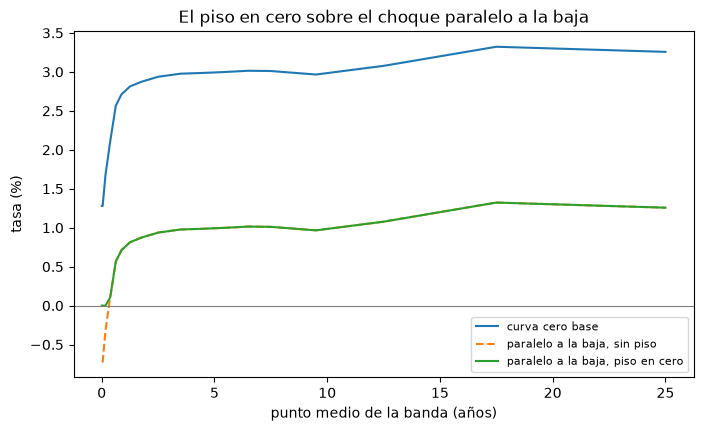

In [9]:
# Aplicar el piso en cero al choque paralelo a la baja y listar dónde actúa el piso bajo cada choque
r0 = np.array(out14["curve"]["zero_rates_at_midpoints"])
floor = out14["scenarios"][0]["floor"]
raw = shocks.apply_floor(r0, shapes["parallel-down"], None)
floored = shocks.apply_floor(r0, shapes["parallel-down"], floor)
print(f"{'banda':>6s} {'tasa base':>12s} {'con choque, sin piso':>20s} {'con choque, piso 0':>20s}")
for k in range(5):
    print(f"{k + 1:6d} {r0[k]:12.5f} {raw[k]:20.5f} {floored[k]:20.5f}")
for s in shocks.SHOCKS:
    gap = shocks.apply_floor(r0, shapes[s], floor) - shocks.apply_floor(r0, shapes[s], None)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(gap) > 1e-12)]
    print(f"{NAME[s]:22s} bandas donde el piso en cero actúa: {bound}")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(MID, r0 * 100, label="curva cero base")
ax.plot(MID, raw * 100, linestyle="--", label="paralelo a la baja, sin piso")
ax.plot(MID, floored * 100, label="paralelo a la baja, piso en cero")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("tasa (%)")
ax.set_title("El piso en cero sobre el choque paralelo a la baja")
ax.legend(fontsize=8)
plt.show()

La curva base es la del 2022-06-30, 1,28 por ciento en las primeras bandas, así que el choque a la baja de 200 pb llevaría las tasas cortas a cerca de -0,72 por ciento; la línea continua muestra al piso devolviéndolas a cero en las tres primeras bandas, y desde la cuarta banda la curva está sobre el piso y el choque pasa intacto. La lista impresa arriba muestra la misma lógica para los otros choques: el piso actúa solo donde una forma a la baja encuentra una tasa baja, nunca bajo las formas al alza. La imagen muestra una curva en un día; en un día con tasas cortas más altas el piso no actúa en ninguna parte, y en un día con tasas negativas importa la regla de que un piso nunca eleva una tasa por encima de su propio nivel.

La misma comparación con el piso dependiente del plazo de la Unión Europea. La celda siguiente imprime su valor en algunos plazos y lista las bandas donde actuaría para cada uno de los seis choques sobre la misma curva. Es un qué pasaría si sobre la curva versionada: los escenarios versionados usan el piso en cero.

piso UE a 0, 1, 5, 10, 25, 50 y 60 años: [-0.015, -0.0147, -0.0135, -0.012, -0.0075, 0.0, 0.0]
paralelo al alza       bandas donde el piso UE actúa: []
paralelo a la baja     bandas donde el piso UE actúa: []
empinamiento           bandas donde el piso UE actúa: []
aplanamiento           bandas donde el piso UE actúa: []
corto al alza          bandas donde el piso UE actúa: []
corto a la baja        bandas donde el piso UE actúa: [1, 2]


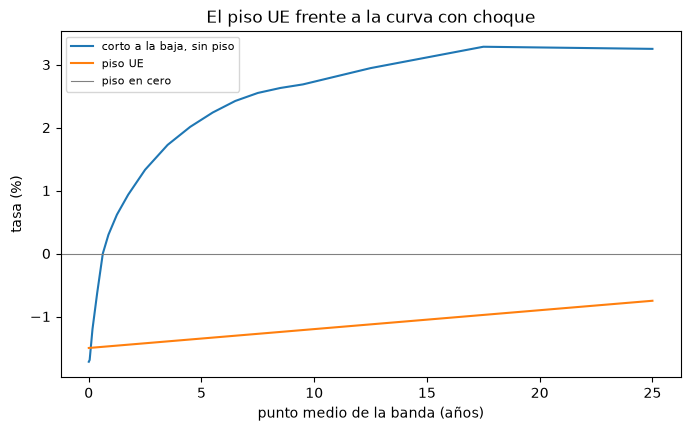

In [10]:
# El piso del plazo de la Unión Europea, y las bandas donde actúa bajo los seis choques
maturities = np.array([0.0, 1.0, 5.0, 10.0, 25.0, 50.0, 60.0])
print("piso UE a 0, 1, 5, 10, 25, 50 y 60 años:", [round(float(x), 4) for x in shocks.eu_floor(maturities)])
eu = shocks.eu_floor(MID)
for s in shocks.SHOCKS:
    gap = shocks.apply_floor(r0, shapes[s], eu) - shocks.apply_floor(r0, shapes[s], None)
    bound = [int(k) + 1 for k in np.flatnonzero(np.abs(gap) > 1e-12)]
    print(f"{NAME[s]:22s} bandas donde el piso UE actúa: {bound}")
shocked = r0 + shapes["short-down"] / 1e4
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(MID, shocked * 100, label="corto a la baja, sin piso")
ax.plot(MID, eu * 100, label="piso UE")
ax.axhline(0, color="grey", linewidth=0.8, label="piso en cero")
ax.set_xlabel("punto medio de la banda (años)")
ax.set_ylabel("tasa (%)")
ax.set_title("El piso UE frente a la curva con choque")
ax.legend(fontsize=8)
plt.show()

El piso europeo parte en -1,5 por ciento a la vista y sube a cero a los 50 años, así que es mucho más laxo que el piso en cero en las bandas cortas: el choque corto a la baja lleva a las dos primeras bandas a cerca de -1,7 por ciento, bajo el -1,5 por ciento que el piso permite, y son las únicas dos bandas donde actúa. La figura muestra además por qué el piso dependiente del plazo importa poco para una curva en dólares a estos niveles: desde la tercera banda la curva con choque está sobre él. Es un qué pasaría sobre la curva versionada, ya que los escenarios versionados usan el piso en cero; la figura no dice qué piso exigirá un supervisor, solo cuánto cambia la elección a la curva con choque.

## Resultados

**Respuesta:** las seis formas mueven la curva en dólares muy distinto a lo largo de las 19 bandas, y la recalibración de 2024 movió a las rotaciones al subir un tamaño. El empinamiento llega a +134,36 pb en la banda de 25 años con los tamaños de 2016 y a +201,73 pb con los de 2024, porque el tamaño largo pasó de 150 a 225 pb. El piso en cero actúa entonces en las bandas 1 a 3 bajo el choque paralelo a la baja, con la tasa base de 0,01279 en la banda 1 llevada de -0,00721 de vuelta a cero.

- **Los escalares y el ejemplo.** A 3,5 años el escalar corto es 0,4169 (el estándar imprime 0,417) y el largo 0,5831. Con tamaños de 100 pb el choque corto es 41,69 pb, el empinamiento +25,39 pb y el aplanamiento -1,64 pb, cada uno igual al cálculo a mano de la definición. La prueba `irrbb.srp31_92_goldens` tiene desviaciones de 0,0001, 0,0138, 0,0136 y 0,0393 frente a las tolerancias de 0,0005 y 0,05, con una mayor desviación de 0,0393; el aplanamiento es el más lejano del valor impreso porque el estándar redondea a un decimal (-1,6393 frente a -1,6). La compuerta es entonces "igual a la precisión impresa", no "igual hasta el último dígito".
- **Los tamaños.** Para el USD solo se mueve el tamaño largo entre las calibraciones (150 pb en 2016, 225 pb en 2024); para el EUR se mueven los tres (200/250/100 a 225/350/200); el JPY no se mueve. Las dos tablas de Basilea tienen 21 monedas y ninguna tiene el peso, así que el motor rechaza un tamaño para él en vez de inventarlo; la tabla chilena da al peso 300/400/200 pb y a la UF 200/250/150 pb para el EVE. Un validador debe leer el origen de cada tamaño antes de leer cualquier resultado: dice de quién es el número.
- **Las formas.** El empinamiento es la forma que más mueve la recalibración. El aplanamiento, en cambio, es grande en el extremo corto (+239,74 pb en la banda 1) y negativo en el largo (-134,28 pb en la banda 19), y los choques cortos parten en 299,79 pb a la vista y se desvanecen hasta 0,58 pb.
- **Los pisos.** El piso en cero actúa en las bandas 1 a 3 bajo el choque paralelo a la baja y el empinamiento, y en las bandas 1 a 4 bajo el choque corto a la baja; nunca actúa bajo los choques al alza ni el aplanamiento. El piso dependiente del plazo de la Unión Europea parte en -0,015 y actúa solo bajo el choque corto a la baja, en las bandas 1 y 2. El piso cambia la curva con choque, así que cambia todo delta EVE que la lee.
- **Lo que el notebook no muestra.** Cómo llega una forma a los flujos para dar un cambio de EVE (notebooks 03 y 06), los tamaños de los choques de NII más allá del único paralelo, y la calibración de los propios tamaños, que el estándar describe en SRP98 y el motor toma como datos.

## Resumen

- Las seis formas salen de dos escalares, $e^{-t/4}$ y su complemento, y tres tamaños por moneda: los choques paralelo y corto usan un escalar cada uno, y el empinamiento y el aplanamiento rotan con los pesos -0,65 y +0,9, y +0,8 y -0,6.
- El ejemplo del propio estándar, 0,417, +41,7 pb, +25,4 pb y -1,6 pb a 3,5 años, es una prueba de valores de referencia del motor, dentro de su tolerancia, y el aplanamiento es el valor más lejano del impreso.
- Los tamaños son una tabla: dos calibraciones de Basilea, 2016 y 2024, y la tabla chilena. Una moneda sin entrada se rechaza, y una estimación lleva su etiqueta y su método.
- Un piso nunca eleva una tasa por encima de su valor previo al choque; el piso en cero actúa en las bandas cortas de la curva del USD de mediados de 2022 bajo los choques a la baja, y el piso UE dependiente del plazo actúa solo bajo el choque corto a la baja, en dos bandas.

**Qué probar a continuación.** Cambia el tamaño largo de `shock_curve` y mira cuál de las dos rotaciones se mueve más. Después sigue con el notebook 03, la capa de comportamiento.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 a SRP31.93 (los seis choques, los tamaños y el piso) y SRP31.96 (las 19 bandas de tiempo). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, Anexo 2, Tabla 1 (la calibración de 2016). https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book (la calibración de 2024, vigente desde 2026-01-01). https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1, hoja 9 (los tamaños de choque chilenos), según se transcriben en el motor y en el dossier 03, F.2.
- Reglamento Delegado (UE) 2024/856 de la Comisión, artículo 3(7) (el piso dependiente del plazo), según lo cita el motor. https://eur-lex.europa.eu/eli/reg_del/2024/856/oj/eng
- Dossier 01 de la investigación de Contraste (marco de Basilea), secciones H.2 a H.3.